# K-Means vs DBSCAN : Clustering Algorith comparison

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans , DBSCAN
from sklearn.datasets import make_moons , make_blobs

In [3]:
x , y_true = make_moons(n_samples=500 , noise=0.05 , random_state=42)
df = pd.DataFrame(x , columns = ["Feature1" , "Feature2"])
df.head()

,Feature1,Feature2
0,0.830586,-0.447733
1,0.701678,0.816918
2,1.022080,-0.492571
3,-0.316765,0.953438
4,0.293226,1.057185


In [4]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

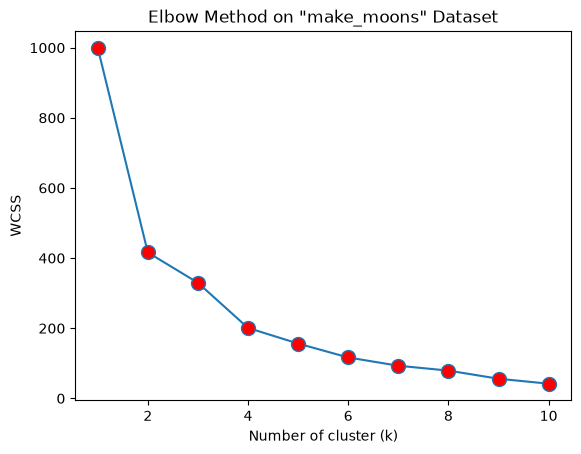

In [5]:
wcss = []
k_range = range(1,11)
for k in k_range:
    kmean = KMeans(n_clusters = k,
                   random_state = 42)
    kmean.fit(x_scaled)
    wcss.append(kmean.inertia_)
plt.plot(k_range , wcss , marker = 'o' , markersize = 10 , markerfacecolor = 'red')
plt.title('Elbow Method on "make_moons" Dataset')
plt.xlabel("Number of cluster (k)")
plt.ylabel("WCSS")
plt.show()

**Conclusion:**
The Elbow Method does not show a clear elbow point for the make_moons dataset. The WCSS decreases gradually as the number of clusters increases, making it difficult to determine the optimal value of K using the Elbow Method alone. This is because make_moons contains non-linear and irregularly shaped clusters. Therefore, K-Means may not be the most suitable choice for this type of dataset, and density-based algorithms such as DBSCAN can be more effective.

In [5]:
kmean = KMeans(n_clusters=2 , random_state=42)
kmean_label = kmean.fit_predict(x_scaled)


In [6]:
dbscan = DBSCAN(eps = 0.3 , min_samples=5)
dbscan_label = dbscan.fit_predict(x_scaled)

In [7]:
df["Kmean_Label"] = kmean_label
df["Dbscan_Label"] = dbscan_label
df

,Feature1,Feature2,Kmean_Label,Dbscan_Label
0,0.830586,-0.447733,1,0
1,0.701678,0.816918,0,1
2,1.022080,-0.492571,1,0
3,-0.316765,0.953438,0,1
4,0.293226,1.057185,0,1
...,...,...,...,...
495,0.239754,0.985462,0,1
496,0.072145,0.184834,0,0
497,0.590273,-0.365577,1,0
498,1.619465,-0.283658,1,0


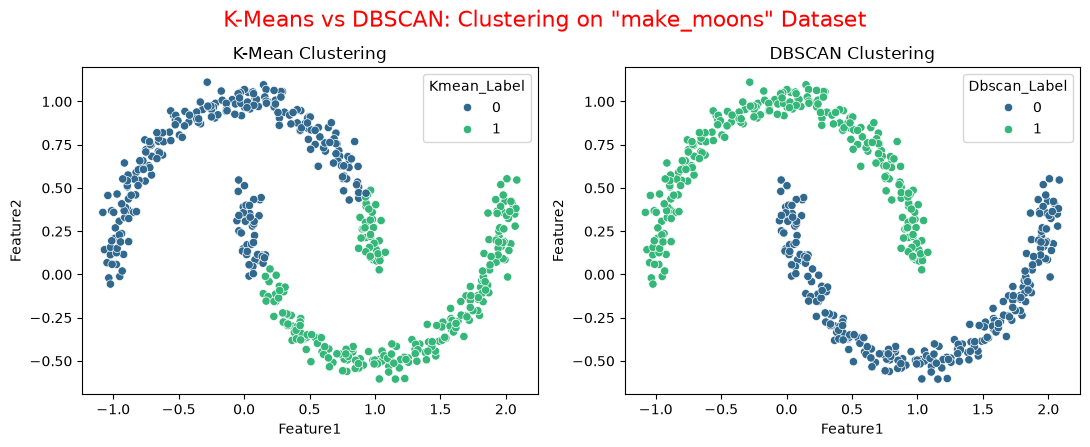

In [8]:
plt.figure(figsize=(11,8))
plt.suptitle('K-Means vs DBSCAN: Clustering on "make_moons" Dataset' , fontsize = 16 , color = 'red')
plt.subplot(2,2,1)
sns.scatterplot(x = df["Feature1"] , y = df["Feature2"] , hue = df["Kmean_Label"] , palette="viridis")
plt.title("K-Mean Clustering")
plt.subplot(2,2,2)
sns.scatterplot(x = df["Feature1"] , y = df["Feature2"] , hue = df["Dbscan_Label"] , palette="viridis")
plt.title("DBSCAN Clustering")
plt.tight_layout()
plt.show()

**Conclusion** :
The results show that K-Means struggles with the make_moons dataset because the clusters have a non-linear and irregular shape. K-Means divides the data based on distance and tends to create relatively simple boundaries. In contrast, DBSCAN successfully identifies the two moon-shaped clusters because it groups data points based on density. Therefore, DBSCAN is more suitable than K-Means for non-linear and irregularly shaped datasets like make_moons.

In [6]:
x , y_true = make_blobs(n_samples=500 , n_features=2 , centers=3 , cluster_std=1.0, random_state=42)
df = pd.DataFrame(x , columns=["Feature1","Feature2"])
df.head()

,Feature1,Feature2
0,-5.730354,-7.583286
1,1.942992,1.918875
2,6.829682,1.164871
3,-2.901306,7.550771
4,5.841093,1.565094


In [7]:
x_scaled = scaler.fit_transform(x)

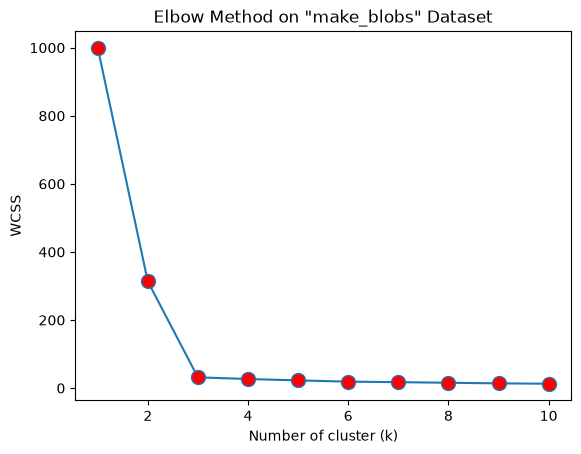

In [8]:
wcss = []
k_range = range(1,11)
for k in k_range:
    kmean = KMeans(n_clusters = k,
                   random_state = 42)
    kmean.fit(x_scaled)
    wcss.append(kmean.inertia_)
plt.plot(k_range , wcss , marker = 'o' , markersize = 10 , markerfacecolor = 'red')
plt.title('Elbow Method on "make_blobs" Dataset')
plt.xlabel("Number of cluster (k)")
plt.ylabel("WCSS")
plt.show()

**Conclusion:**
The Elbow Method shows a clear elbow at k = 3, indicating that 3 clusters are a suitable choice for the make_blobs dataset. After k = 3, the WCSS decreases only slightly, so increasing the number of clusters provides little additional improvement. Therefore, K = 3 is selected for K-Means clustering.

In [12]:
kmean = KMeans(n_clusters=3 , random_state=42)
kmean_label = kmean.fit_predict(x_scaled)

In [13]:
dbscan = DBSCAN(eps = 0.3 , min_samples=5)
dbscan_label = dbscan.fit_predict(x_scaled)

In [14]:
df["Dbscan_Label"] = dbscan_label
df["K-mean_Label"] = kmean_label

Text(0.5, 1.0, 'DBSCAN Clustering')

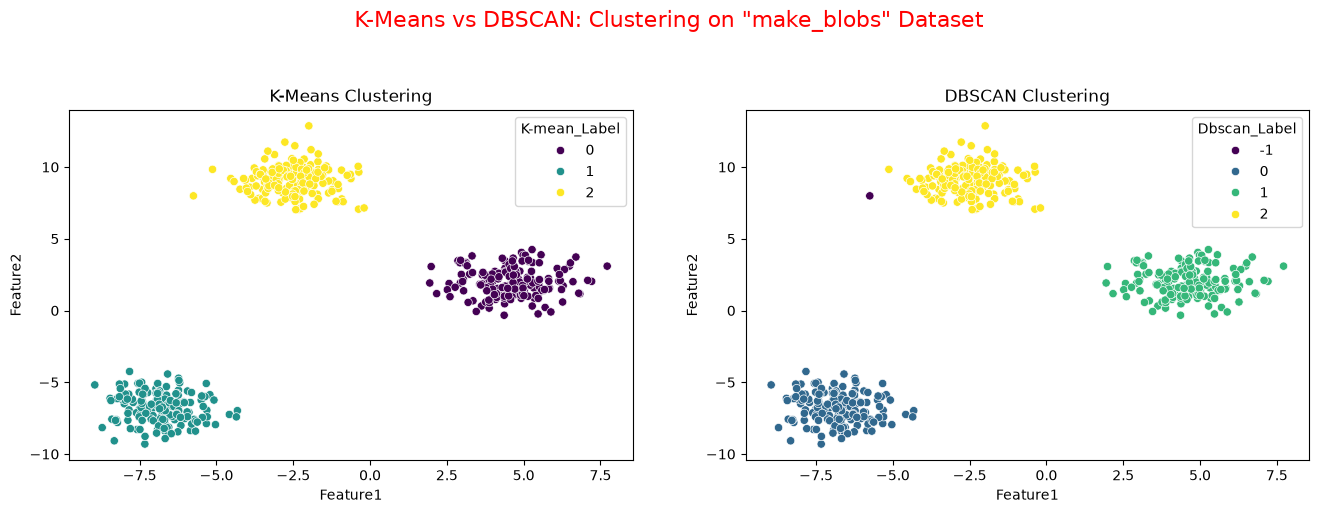

In [15]:
plt.figure(figsize=(16,10))
plt.suptitle('K-Means vs DBSCAN: Clustering on "make_blobs" Dataset' , fontsize = 16 , color = 'red')
plt.subplot(2,2,1)
sns.scatterplot(x = df["Feature1"] , y = df["Feature2"] , hue = df["K-mean_Label"] , palette="viridis")
plt.title("K-Means Clustering")
plt.subplot(2,2,2)
sns.scatterplot(x = df["Feature1"] , y = df["Feature2"] , hue = df["Dbscan_Label"] , palette="viridis")
plt.title("DBSCAN Clustering")

**Conclusion:**
The results show that both K-Means and DBSCAN perform well on the make_blobs dataset because the clusters are well-separated and approximately spherical. K-Means successfully identifies the three clusters, while DBSCAN also detects the clusters based on data density and can additionally identify noise points. Therefore, for well-separated blob-shaped data, both algorithms can provide good clustering results.